In [4]:
# !pip install accelerate

In [8]:
import os
from pathlib import Path

# Set GPU before importing torch
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import torch
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from tqdm import tqdm
import random
import json
import requests

In [9]:
import torch
print(torch.cuda.is_available())
print(os.environ["CUDA_VISIBLE_DEVICES"])

True
0


In [10]:
torch.backends.cuda.enable_mem_efficient_sdp(False)
torch.backends.cuda.enable_flash_sdp(False)

print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"Total GPUs seen: {torch.cuda.device_count()}")
print(f"Using Device: {torch.cuda.get_device_name(0)}") # Should say A100

CUDA Available: True
Total GPUs seen: 1
Using Device: NVIDIA A100 80GB PCIe MIG 3g.40gb


In [5]:
url = "https://raw.githubusercontent.com/albertan017/LLM4Decompile/refs/heads/main/legacy-test/decompile-eval-executable-gcc-obj.json"
response = requests.get(url)
dataset = response.json()
samples = list(dataset)
random.seed(42)
num_samples = 100
samples = samples[:num_samples]
# print(f"total samples {len(samples)}")
# print(samples)
# for  samples_idx, item in enumerate(tqdm(samples, desc="Processing samples")):
#     # ghidra_code = item["c_func"]
#     target_code = item.get("input_asm_prompt", "")
#     print(target_code)

TOKEN RANK ANALYSIS - llm4decompile-6.7b-v1.5

Loading llm4decompile-6.7b-v1.5...


Loading checkpoint shards: 100%|██████████| 3/3 [00:02<00:00,  1.30it/s]


Model loaded. Vocab size: 32,256

Loading dataset...
Using 100 samples


Processing samples: 100%|██████████| 100/100 [00:29<00:00,  3.42it/s]



RESULTS

OVERALL STATISTICS (100 samples, 11208 total tokens):
  Overall median rank: 1.0
  Overall mean rank: 5.5
  Rank 1 (exact match): 9810 / 11208 (87.5%)
  Rank <= 5: 10899 / 11208 (97.2%)
  Rank <= 10: 10976 / 11208 (97.9%)
  Rank <= 100: 11098 / 11208 (99.0%)
  Rank > 100: 110 / 11208 (1.0%)
  Rank > 1000: 6 / 11208 (0.1%)

Generating plots...

Plot saved to: /home/stu354543/outputs/output_rq1_c2/token_rank_analysis.png
Raw data saved to: /home/stu354543/outputs/output_rq1_c2/token_rank_data.npz


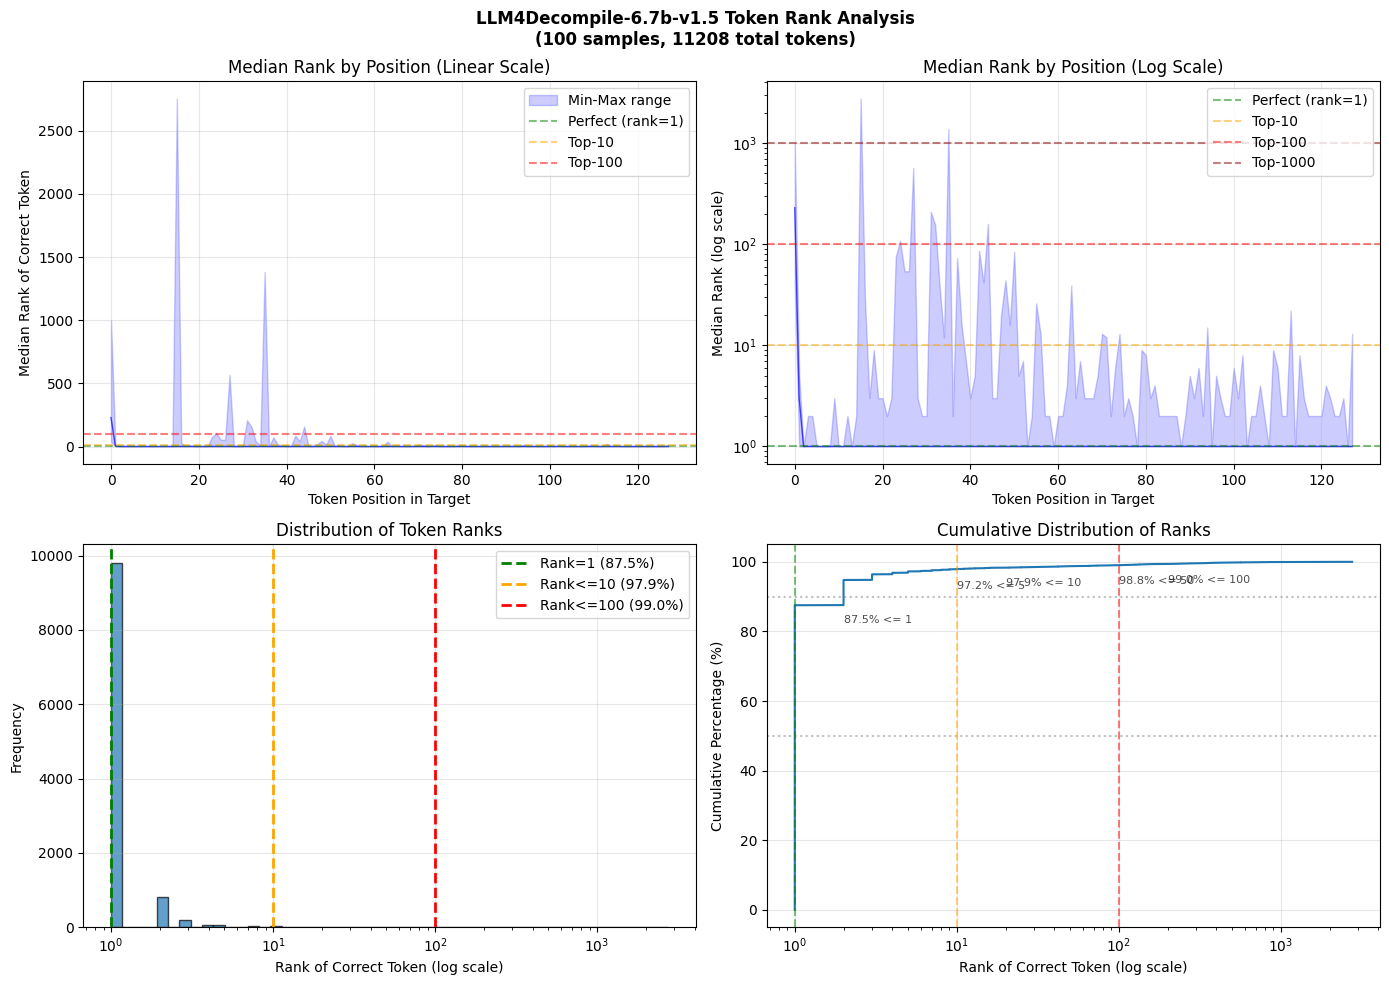

In [8]:
# for RQ1_C2: Run token rank analysis: ASM + HumanEval-Decompile — use llm4decompile-6.7b-v1.5, feed decompile-eval-executable-gcc-obj.json
device = "cuda:0"
num_samples = 100
max_target_tokens = 128

# max_memory = {0: "20GiB",
#               1: "14GiB",
#               "cpu": "32GiB"}
output_dir = "/home/stu354543/outputs/output_rq1_c2"
print("=" * 70)
print("TOKEN RANK ANALYSIS - llm4decompile-6.7b-v1.5")
print("=" * 70)

# Load model
print("\nLoading llm4decompile-6.7b-v1.5...")
model_name = "LLM4Binary/llm4decompile-6.7b-v1.5"

tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map=device,
    # max_memory = max_memory,
    # offload_folder = "offload",
    # offload_state_dict = True,
    trust_remote_code=True,
)
model.eval()

vocab_size = model.config.vocab_size
print(f"Model loaded. Vocab size: {vocab_size:,}")

# Load dataset
print("\nLoading dataset...")
# dataset = load_dataset("LLM4Binary/decompile-eval", split="train")
# samples = list(dataset)
random.seed(42)
random.shuffle(samples)
samples = samples[:num_samples]
print(f"Using {num_samples} samples")

# ranks_by_position[pos] = list of ranks from different samples
ranks_by_position = {}

for sample_idx, item in enumerate(tqdm(samples, desc="Processing samples")):
    asm_code = item["input_asm_prompt"]
    target_code = item["c_func"]

    # Format prompt (same as LLM4Decompile expects)
    prompt = f"# This is asm code:\n{asm_code}\n# What is the source code?\n"

    # Tokenize prompt and target separately
    prompt_tokens = tokenizer.encode(prompt, add_special_tokens=True)
    target_tokens = tokenizer.encode(target_code, add_special_tokens=False)
    target_tokens = target_tokens[:max_target_tokens]

    # Single forward pass with teacher forcing.
    # Input: [prompt..., t0, t1, ..., t_{n-1}]
    # logits[i] predicts token at position i+1
    # So logits[prompt_len-1] predicts t0, logits[prompt_len] predicts t1, etc.
    full_input = prompt_tokens + target_tokens
    input_ids = torch.tensor([full_input], dtype=torch.long, device=device)

    with torch.no_grad():
        outputs = model(input_ids)
        start_idx = len(prompt_tokens) - 1
        end_idx = start_idx + len(target_tokens)
        target_logits = outputs.logits[0, start_idx:end_idx, :]  # [target_len, vocab]

    # Vectorized rank computation
    target_tensor = torch.tensor(target_tokens, dtype=torch.long, device=device)
    probs = torch.softmax(target_logits, dim=-1)
    correct_probs = probs[torch.arange(len(target_tokens), device=device), target_tensor]

    # Rank = 1 + count of tokens with higher probability
    ranks = 1 + (probs > correct_probs.unsqueeze(1)).sum(dim=1)
    sample_ranks = ranks.cpu().tolist()

    for pos, rank in enumerate(sample_ranks):
        if pos not in ranks_by_position:
            ranks_by_position[pos] = []
        ranks_by_position[pos].append(rank)

# Compute statistics by position
print("\n" + "=" * 70)
print("RESULTS")
print("=" * 70)

positions = sorted(ranks_by_position.keys())
median_ranks = []
mean_ranks = []
min_ranks = []
max_ranks = []

for pos in positions:
    r = ranks_by_position[pos]
    median_ranks.append(np.median(r))
    mean_ranks.append(np.mean(r))
    min_ranks.append(np.min(r))
    max_ranks.append(np.max(r))

all_ranks = []
for pos in positions:
    all_ranks.extend(ranks_by_position[pos])
all_ranks = np.array(all_ranks)

print(f"\nOVERALL STATISTICS ({num_samples} samples, {len(all_ranks)} total tokens):")
print(f"  Overall median rank: {np.median(all_ranks):.1f}")
print(f"  Overall mean rank: {np.mean(all_ranks):.1f}")
print(f"  Rank 1 (exact match): {(all_ranks == 1).sum()} / {len(all_ranks)} ({100*(all_ranks == 1).mean():.1f}%)")
print(f"  Rank <= 5: {(all_ranks <= 5).sum()} / {len(all_ranks)} ({100*(all_ranks <= 5).mean():.1f}%)")
print(f"  Rank <= 10: {(all_ranks <= 10).sum()} / {len(all_ranks)} ({100*(all_ranks <= 10).mean():.1f}%)")
print(f"  Rank <= 100: {(all_ranks <= 100).sum()} / {len(all_ranks)} ({100*(all_ranks <= 100).mean():.1f}%)")
print(f"  Rank > 100: {(all_ranks > 100).sum()} / {len(all_ranks)} ({100*(all_ranks > 100).mean():.1f}%)")
print(f"  Rank > 1000: {(all_ranks > 1000).sum()} / {len(all_ranks)} ({100*(all_ranks > 1000).mean():.1f}%)")

# --- Plots ---
print("\nGenerating plots...")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Median rank by position (linear)
ax1 = axes[0, 0]
ax1.plot(positions, median_ranks, "b-", linewidth=1, alpha=0.7)
ax1.fill_between(positions, min_ranks, max_ranks, alpha=0.2, color="blue", label="Min-Max range")
ax1.axhline(y=1, color="green", linestyle="--", alpha=0.5, label="Perfect (rank=1)")
ax1.axhline(y=10, color="orange", linestyle="--", alpha=0.5, label="Top-10")
ax1.axhline(y=100, color="red", linestyle="--", alpha=0.5, label="Top-100")
ax1.set_xlabel("Token Position in Target")
ax1.set_ylabel("Median Rank of Correct Token")
ax1.set_title("Median Rank by Position (Linear Scale)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Median rank by position (log)
ax2 = axes[0, 1]
ax2.semilogy(positions, median_ranks, "b-", linewidth=1, alpha=0.7)
ax2.fill_between(positions, min_ranks, max_ranks, alpha=0.2, color="blue")
ax2.axhline(y=1, color="green", linestyle="--", alpha=0.5, label="Perfect (rank=1)")
ax2.axhline(y=10, color="orange", linestyle="--", alpha=0.5, label="Top-10")
ax2.axhline(y=100, color="red", linestyle="--", alpha=0.5, label="Top-100")
ax2.axhline(y=1000, color="darkred", linestyle="--", alpha=0.5, label="Top-1000")
ax2.set_xlabel("Token Position in Target")
ax2.set_ylabel("Median Rank (log scale)")
ax2.set_title("Median Rank by Position (Log Scale)")
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Histogram of all ranks
ax3 = axes[1, 0]
bins = np.logspace(0, np.log10(max(all_ranks) + 1), 50)
ax3.hist(all_ranks, bins=bins, edgecolor="black", alpha=0.7)
ax3.set_xscale("log")
ax3.axvline(x=1, color="green", linestyle="--", linewidth=2, label=f"Rank=1 ({100*(all_ranks==1).mean():.1f}%)")
ax3.axvline(x=10, color="orange", linestyle="--", linewidth=2, label=f"Rank<=10 ({100*(all_ranks<=10).mean():.1f}%)")
ax3.axvline(x=100, color="red", linestyle="--", linewidth=2, label=f"Rank<=100 ({100*(all_ranks<=100).mean():.1f}%)")
ax3.set_xlabel("Rank of Correct Token (log scale)")
ax3.set_ylabel("Frequency")
ax3.set_title("Distribution of Token Ranks")
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Cumulative distribution
ax4 = axes[1, 1]
sorted_ranks = np.sort(all_ranks)
cumulative = np.arange(1, len(sorted_ranks) + 1) / len(sorted_ranks)
ax4.semilogx(sorted_ranks, cumulative * 100)
ax4.axhline(y=50, color="gray", linestyle=":", alpha=0.5)
ax4.axhline(y=90, color="gray", linestyle=":", alpha=0.5)
ax4.axvline(x=1, color="green", linestyle="--", alpha=0.5)
ax4.axvline(x=10, color="orange", linestyle="--", alpha=0.5)
ax4.axvline(x=100, color="red", linestyle="--", alpha=0.5)
ax4.set_xlabel("Rank of Correct Token (log scale)")
ax4.set_ylabel("Cumulative Percentage (%)")
ax4.set_title("Cumulative Distribution of Ranks")
ax4.grid(True, alpha=0.3)

for threshold in [1, 5, 10, 50, 100]:
    pct = 100 * (all_ranks <= threshold).mean()
    ax4.annotate(
        f"{pct:.1f}% <= {threshold}",
        xy=(threshold, pct),
        xytext=(threshold * 2, pct - 5),
        fontsize=8,
        alpha=0.7,
    )

plt.suptitle(
    f"LLM4Decompile-6.7b-v1.5 Token Rank Analysis\n({num_samples} samples, {len(all_ranks)} total tokens)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()

plot_path = Path(output_dir) / "token_rank_analysis.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
print(f"\nPlot saved to: {plot_path}")

data_path = Path(output_dir) / "token_rank_data.npz"
np.savez(
    data_path,
    positions=np.array(positions),
    median_ranks=np.array(median_ranks),
    mean_ranks=np.array(mean_ranks),
    min_ranks=np.array(min_ranks),
    max_ranks=np.array(max_ranks),
    all_ranks=all_ranks,
)
print(f"Raw data saved to: {data_path}")

TOKEN RANK ANALYSIS - LLM4Decompile-9b-v2

Loading LLM4Decompile-9b-v2...


Loading checkpoint shards: 100%|██████████| 4/4 [00:02<00:00,  1.40it/s]


Model loaded. Vocab size: 64,000

Loading dataset...
Using 100 samples


Processing samples: 100%|██████████| 100/100 [00:57<00:00,  1.74it/s]



RESULTS

OVERALL STATISTICS (100 samples, 11441 total tokens):
  Overall median rank: 1.0
  Overall mean rank: 15.8
  Rank 1 (exact match): 9254 / 11441 (80.9%)
  Rank <= 5: 10717 / 11441 (93.7%)
  Rank <= 10: 10935 / 11441 (95.6%)
  Rank <= 100: 11293 / 11441 (98.7%)
  Rank > 100: 148 / 11441 (1.3%)
  Rank > 1000: 18 / 11441 (0.2%)

Generating plots...

Plot saved to: /home/stu354543/outputs/output_rq1_c1/token_rank_analysis.png
Raw data saved to: /home/stu354543/outputs/output_rq1_c1/token_rank_data.npz


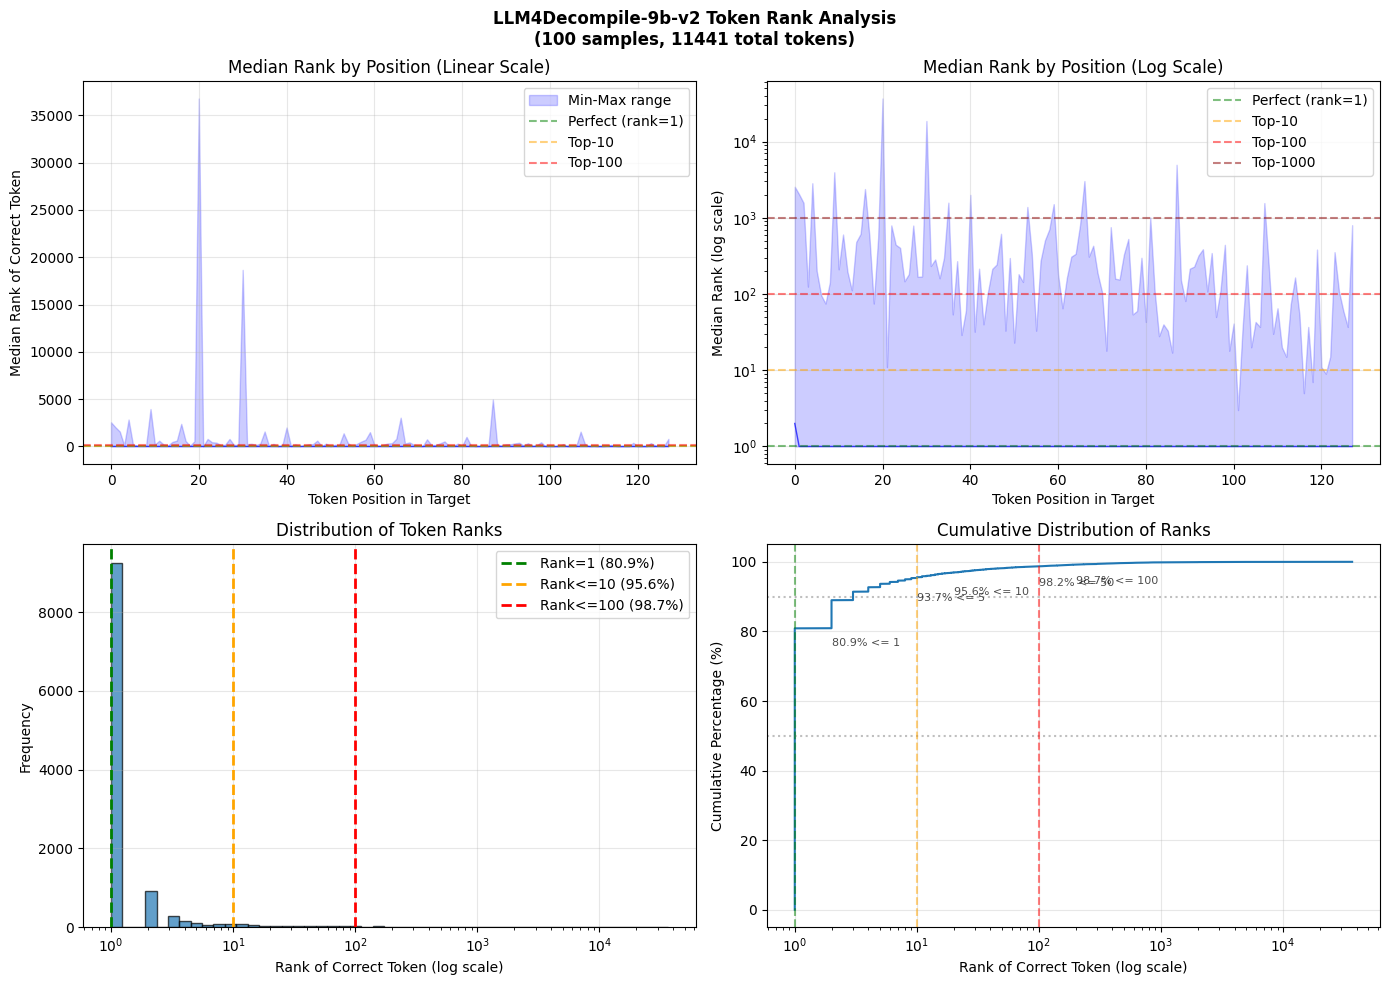

In [11]:
#RQ1:(C1) Run token rank analysis: Ghidra + HumanEval-Decompile — upgrade from llm4decompile-6.7b-v2 to llm4decompile-9b-v2
device = "cuda:0"
num_samples = 100
max_target_tokens = 128

output_dir = Path("/home/stu354543/outputs/output_rq1_c1")
print("=" * 70)
print("TOKEN RANK ANALYSIS - LLM4Decompile-9b-v2")
print("=" * 70)

# Load model
print("\nLoading LLM4Decompile-9b-v2...")
model_name = "LLM4Binary/llm4decompile-9b-v2"

tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    trust_remote_code=True,
)
model.eval()

vocab_size = model.config.vocab_size
print(f"Model loaded. Vocab size: {vocab_size:,}")

# Load dataset
print("\nLoading dataset...")
dataset = load_dataset("LLM4Binary/decompile-eval", split="train")
samples = list(dataset)
random.seed(42)
random.shuffle(samples)
samples = samples[:num_samples]
print(f"Using {num_samples} samples")

# ranks_by_position[pos] = list of ranks from different samples
ranks_by_position = {}

for sample_idx, item in enumerate(tqdm(samples, desc="Processing samples")):
    ghidra_code = item["ghidra_pseudo"]
    target_code = item["func"]

    # Format prompt (same as LLM4Decompile expects)
    prompt = f"# This is the assembly code:\n{ghidra_code}\n# What is the source code?\n"

    # Tokenize prompt and target separately
    prompt_tokens = tokenizer.encode(prompt, add_special_tokens=True)
    target_tokens = tokenizer.encode(target_code, add_special_tokens=False)
    target_tokens = target_tokens[:max_target_tokens]

    # Single forward pass with teacher forcing.
    # Input: [prompt..., t0, t1, ..., t_{n-1}]
    # logits[i] predicts token at position i+1
    # So logits[prompt_len-1] predicts t0, logits[prompt_len] predicts t1, etc.
    full_input = prompt_tokens + target_tokens
    input_ids = torch.tensor([full_input], dtype=torch.long, device=device)

    with torch.no_grad():
        outputs = model(input_ids)
        start_idx = len(prompt_tokens) - 1
        end_idx = start_idx + len(target_tokens)
        target_logits = outputs.logits[0, start_idx:end_idx, :]  # [target_len, vocab]

    # Vectorized rank computation
    target_tensor = torch.tensor(target_tokens, dtype=torch.long, device=device)
    probs = torch.softmax(target_logits, dim=-1)
    correct_probs = probs[torch.arange(len(target_tokens), device=device), target_tensor]

    # Rank = 1 + count of tokens with higher probability
    ranks = 1 + (probs > correct_probs.unsqueeze(1)).sum(dim=1)
    sample_ranks = ranks.cpu().tolist()

    for pos, rank in enumerate(sample_ranks):
        if pos not in ranks_by_position:
            ranks_by_position[pos] = []
        ranks_by_position[pos].append(rank)

# Compute statistics by position
print("\n" + "=" * 70)
print("RESULTS")
print("=" * 70)

positions = sorted(ranks_by_position.keys())
median_ranks = []
mean_ranks = []
min_ranks = []
max_ranks = []

for pos in positions:
    r = ranks_by_position[pos]
    median_ranks.append(np.median(r))
    mean_ranks.append(np.mean(r))
    min_ranks.append(np.min(r))
    max_ranks.append(np.max(r))

all_ranks = []
for pos in positions:
    all_ranks.extend(ranks_by_position[pos])
all_ranks = np.array(all_ranks)

print(f"\nOVERALL STATISTICS ({num_samples} samples, {len(all_ranks)} total tokens):")
print(f"  Overall median rank: {np.median(all_ranks):.1f}")
print(f"  Overall mean rank: {np.mean(all_ranks):.1f}")
print(f"  Rank 1 (exact match): {(all_ranks == 1).sum()} / {len(all_ranks)} ({100*(all_ranks == 1).mean():.1f}%)")
print(f"  Rank <= 5: {(all_ranks <= 5).sum()} / {len(all_ranks)} ({100*(all_ranks <= 5).mean():.1f}%)")
print(f"  Rank <= 10: {(all_ranks <= 10).sum()} / {len(all_ranks)} ({100*(all_ranks <= 10).mean():.1f}%)")
print(f"  Rank <= 100: {(all_ranks <= 100).sum()} / {len(all_ranks)} ({100*(all_ranks <= 100).mean():.1f}%)")
print(f"  Rank > 100: {(all_ranks > 100).sum()} / {len(all_ranks)} ({100*(all_ranks > 100).mean():.1f}%)")
print(f"  Rank > 1000: {(all_ranks > 1000).sum()} / {len(all_ranks)} ({100*(all_ranks > 1000).mean():.1f}%)")

# --- Plots ---
print("\nGenerating plots...")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Median rank by position (linear)
ax1 = axes[0, 0]
ax1.plot(positions, median_ranks, "b-", linewidth=1, alpha=0.7)
ax1.fill_between(positions, min_ranks, max_ranks, alpha=0.2, color="blue", label="Min-Max range")
ax1.axhline(y=1, color="green", linestyle="--", alpha=0.5, label="Perfect (rank=1)")
ax1.axhline(y=10, color="orange", linestyle="--", alpha=0.5, label="Top-10")
ax1.axhline(y=100, color="red", linestyle="--", alpha=0.5, label="Top-100")
ax1.set_xlabel("Token Position in Target")
ax1.set_ylabel("Median Rank of Correct Token")
ax1.set_title("Median Rank by Position (Linear Scale)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Median rank by position (log)
ax2 = axes[0, 1]
ax2.semilogy(positions, median_ranks, "b-", linewidth=1, alpha=0.7)
ax2.fill_between(positions, min_ranks, max_ranks, alpha=0.2, color="blue")
ax2.axhline(y=1, color="green", linestyle="--", alpha=0.5, label="Perfect (rank=1)")
ax2.axhline(y=10, color="orange", linestyle="--", alpha=0.5, label="Top-10")
ax2.axhline(y=100, color="red", linestyle="--", alpha=0.5, label="Top-100")
ax2.axhline(y=1000, color="darkred", linestyle="--", alpha=0.5, label="Top-1000")
ax2.set_xlabel("Token Position in Target")
ax2.set_ylabel("Median Rank (log scale)")
ax2.set_title("Median Rank by Position (Log Scale)")
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Histogram of all ranks
ax3 = axes[1, 0]
bins = np.logspace(0, np.log10(max(all_ranks) + 1), 50)
ax3.hist(all_ranks, bins=bins, edgecolor="black", alpha=0.7)
ax3.set_xscale("log")
ax3.axvline(x=1, color="green", linestyle="--", linewidth=2, label=f"Rank=1 ({100*(all_ranks==1).mean():.1f}%)")
ax3.axvline(x=10, color="orange", linestyle="--", linewidth=2, label=f"Rank<=10 ({100*(all_ranks<=10).mean():.1f}%)")
ax3.axvline(x=100, color="red", linestyle="--", linewidth=2, label=f"Rank<=100 ({100*(all_ranks<=100).mean():.1f}%)")
ax3.set_xlabel("Rank of Correct Token (log scale)")
ax3.set_ylabel("Frequency")
ax3.set_title("Distribution of Token Ranks")
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Cumulative distribution
ax4 = axes[1, 1]
sorted_ranks = np.sort(all_ranks)
cumulative = np.arange(1, len(sorted_ranks) + 1) / len(sorted_ranks)
ax4.semilogx(sorted_ranks, cumulative * 100)
ax4.axhline(y=50, color="gray", linestyle=":", alpha=0.5)
ax4.axhline(y=90, color="gray", linestyle=":", alpha=0.5)
ax4.axvline(x=1, color="green", linestyle="--", alpha=0.5)
ax4.axvline(x=10, color="orange", linestyle="--", alpha=0.5)
ax4.axvline(x=100, color="red", linestyle="--", alpha=0.5)
ax4.set_xlabel("Rank of Correct Token (log scale)")
ax4.set_ylabel("Cumulative Percentage (%)")
ax4.set_title("Cumulative Distribution of Ranks")
ax4.grid(True, alpha=0.3)

for threshold in [1, 5, 10, 50, 100]:
    pct = 100 * (all_ranks <= threshold).mean()
    ax4.annotate(
        f"{pct:.1f}% <= {threshold}",
        xy=(threshold, pct),
        xytext=(threshold * 2, pct - 5),
        fontsize=8,
        alpha=0.7,
    )

plt.suptitle(
    f"LLM4Decompile-9b-v2 Token Rank Analysis\n({num_samples} samples, {len(all_ranks)} total tokens)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()

plot_path = output_dir / "token_rank_analysis.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
print(f"\nPlot saved to: {plot_path}")

data_path = output_dir / "token_rank_data.npz"
np.savez(
    data_path,
    positions=np.array(positions),
    median_ranks=np.array(median_ranks),
    mean_ranks=np.array(mean_ranks),
    min_ranks=np.array(min_ranks),
    max_ranks=np.array(max_ranks),
    all_ranks=all_ranks,
)
print(f"Raw data saved to: {data_path}")